# Домашнее задание 3: мониторинг ВМ и Docker-образ для бэкенда

## Задание 1. Мониторинг ВМ

| № | Шаг | Требования |
|---|---|---|
| 1 | Node Exporter | запущен, `curl localhost:9100/metrics` отдаёт метрики `node_*` |

In [1]:
%%bash

curl -s http://localhost:9100/metrics | grep '^node_' | head -n 20

node_arp_entries{device="br-e5514e23e782"} 2
node_arp_entries{device="docker0"} 1
node_arp_entries{device="enp0s3"} 1
node_boot_time_seconds 1.792661991e+09
node_context_switches_total 7.721443e+06
node_cooling_device_cur_state{name="0",type="Processor"} 0
node_cooling_device_cur_state{name="1",type="Processor"} 0
node_cooling_device_max_state{name="0",type="Processor"} 0
node_cooling_device_max_state{name="1",type="Processor"} 0
node_cpu_guest_seconds_total{cpu="0",mode="nice"} 0
node_cpu_guest_seconds_total{cpu="0",mode="user"} 0
node_cpu_guest_seconds_total{cpu="1",mode="nice"} 0
node_cpu_guest_seconds_total{cpu="1",mode="user"} 0
node_cpu_seconds_total{cpu="0",mode="idle"} 3768.47
node_cpu_seconds_total{cpu="0",mode="iowait"} 34.4
node_cpu_seconds_total{cpu="0",mode="irq"} 0
node_cpu_seconds_total{cpu="0",mode="nice"} 0.98
node_cpu_seconds_total{cpu="0",mode="softirq"} 60.55
node_cpu_seconds_total{cpu="0",mode="steal"} 0
node_cpu_seconds_total{cpu="0",mode="system"} 198.02


| № | Шаг | Требования |
|---|---|---|
| 2 | Подключение к Prometheus | в `prometheus.yml` есть задание `job_name: node`, у цели понятная метка `instance` (`vm1`, …); на http://localhost:9090/targets цель в состоянии `UP` |

In [2]:
%%bash

curl -s http://localhost:9090/api/v1/targets \
  | jq '[.data.activeTargets[] | {
      job: .labels.job,
      instance: .labels.instance,
      health: .health,
      lastError: .lastError
    }]'

[
  {
    "job": "node",
    "instance": "vm1",
    "health": "up",
    "lastError": ""
  },
  {
    "job": "prometheus",
    "instance": "localhost:9090",
    "health": "up",
    "lastError": ""
  }
]


| № | Задание | Требования |
|---|---|---|
| 3 | Источник данных в Grafana | Prometheus добавлен в **Connections → Data sources**, **Save & test** проходит успешно |

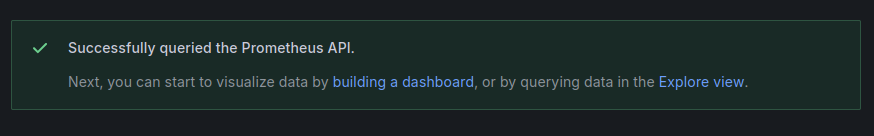

In [3]:
%%bash

curl -s -u admin:admin \
  http://localhost:3000/api/datasources/uid/fg1zbmvi8zgu8d/health | jq .

{
  "details": {
    "application": "Prometheus",
    "features": {
      "rulerApiEnabled": false
    }
  },
  "message": "Successfully queried the Prometheus API.",
  "status": "OK"
}


| № | Задание | Требования |
|---|---|---|
| 4 | Свой дашборд |** созданный вами**, а не импортированный: четыре панели, по 0,5 балла за каждую (см. таблицу ниже)

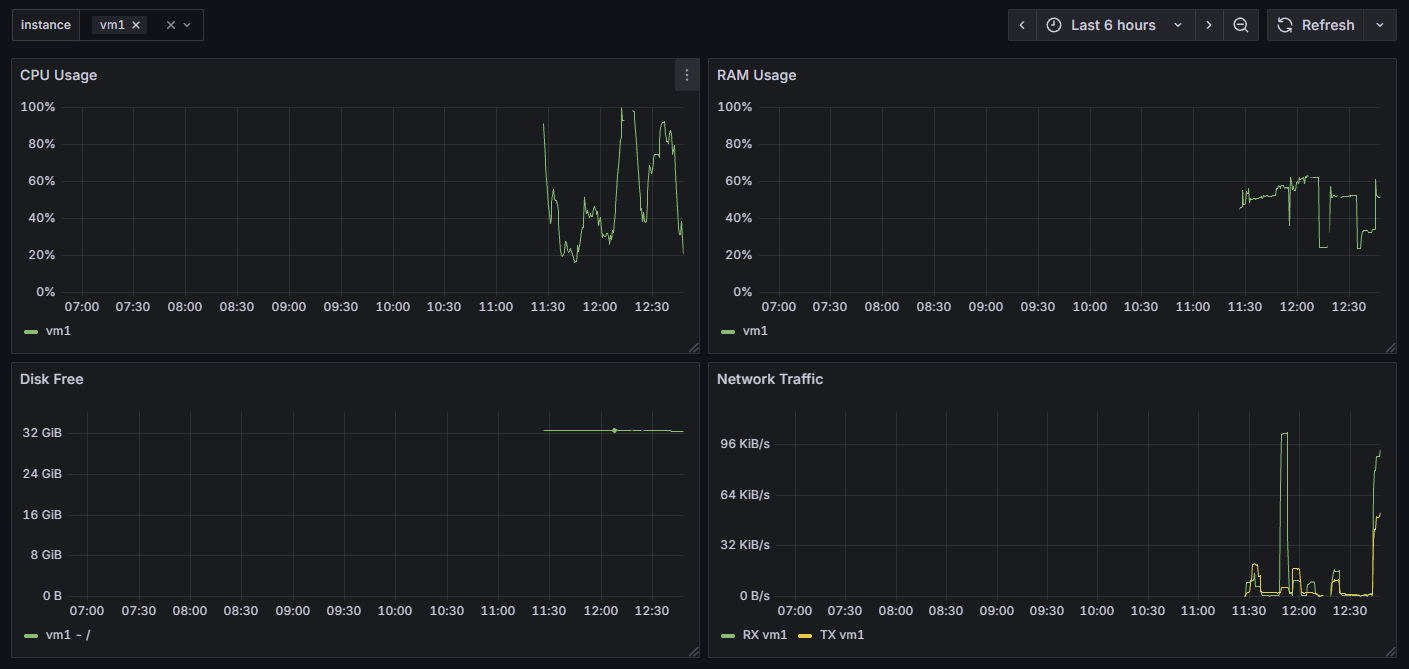

| № | Задание | Требования |
|---|---|---|
| 5 | Переменная и экспорт | на дашборде есть переменная `instance` (выбор ВМ), JSON дашборда выгружен (**Export → Export as JSON**) и лежит в репозитории |

In [4]:
%%bash
set -euo pipefail

FILE="monitoring/export/monitoring.json"

echo "=== Экспортированный дашборд ==="
realpath "$FILE"
ls -lh "$FILE"

echo
echo "=== Переменная instance ==="
jq '.templating.list[]
    | select(.name == "instance")
    | {
        name,
        type,
        query,
        multi,
        includeAll
      }' "$FILE"

echo
echo "=== Панели и использование переменной instance ==="
jq -r '
  .panels[]
  | .title as $title
  | .targets[]
  | "\($title): \(.expr | contains("$instance"))"
' "$FILE"

=== Экспортированный дашборд ===
/home/ubuntu/homework/hw3/monitoring/export/monitoring.json
-rw-rw-r-- 1 ubuntu ubuntu 12K Oct 22 10:37 monitoring/export/monitoring.json



=== Переменная instance ===
{
  "name": "instance",
  "type": "query",
  "query": {
    "qryType": 1,
    "query": "label_values(node_uname_info,instance)",
    "refId": "PrometheusVariableQueryEditor-VariableQuery"
  },
  "multi": true,
  "includeAll": true
}

=== Панели и использование переменной instance ===
CPU Usage: true
RAM Usage: true
Disk Free: true
Network Traffic: true
Network Traffic: true


## Задание 2. Docker-образ для counter-backend

| № | Вариант | Требования |
|---|---|---|
| 1 | `Dockerfile.single` | **без** многоступенчатой сборки, процесс запускается от root|

In [5]:
%%bash

set -e

docker build \
  --no-cache \
  -f counter-backend/Dockerfile.single \
  -t counter-single:latest \
  counter-backend

DEPRECATED: The legacy builder is deprecated and will be removed in a future release.
            Install the buildx component to build images with BuildKit:
            https://docs.docker.com/go/buildx/



Sending build context to Docker daemon  111.1kB
Step 1/10 : FROM python:3.11.6-slim-bookworm
 ---> cc7585194810
Step 2/10 : WORKDIR /app
 ---> Running in 6eee0cb8fdcb
 ---> Removed intermediate container 6eee0cb8fdcb
 ---> 4085d26f23d0
Step 3/10 : RUN python -m pip install     --no-cache-dir     poetry==1.8.5 setuptools wheel
 ---> Running in 5fd4c4f00098
  Obtaining dependency information for poetry==1.8.5 from https://files.pythonhosted.org/packages/45/8e/5e6cbfd7654c93b08423fc62be737a79121fb30ad44e3d9c00292c93fcbb/poetry-1.8.5-py3-none-any.whl.metadata
  Obtaining dependency information for build<2.0.0,>=1.0.3 from https://files.pythonhosted.org/packages/ad/9b/9fb3585dabcd73a1b2a6267f63f62649347c9e6d072c9fde365b105abb2c/build-1.6.1-py3-none-any.whl.metadata
  Obtaining dependency information for cachecontrol[filecache]<0.15.0,>=0.14.0 from https://files.pythonhosted.org/packages/ef/79/c45f2d53efe6ada1110cf6f9fca095e4ff47a0454444aefdde6ac4789179/cachecontrol-0.14.4-py3-none-any.whl.m

In [6]:
%%bash
set -e

docker rm -f counter-single-test 2>/dev/null || true

docker run -d \
  --name counter-single-test \
  -p 8080:8080 \
  counter-single:latest

docker ps --filter "name=counter-single-test"

98a94344fe98f7c7d2c869f1cd7285c803c7b52809eca3a0fadeb039f166490d
CONTAINER ID   IMAGE                   COMMAND                  CREATED        STATUS                  PORTS                                         NAMES
98a94344fe98   counter-single:latest   "python -m counter_b…"   1 second ago   Up Less than a second   0.0.0.0:8080->8080/tcp, [::]:8080->8080/tcp   counter-single-test


In [7]:
%%bash
set -e

echo "=== GET /api/counter ==="
curl -fsS http://localhost:8080/api/counter
echo

echo "=== POST /api/counter ==="
curl -fsS -X POST http://localhost:8080/api/counter
echo

echo "=== GET после POST ==="
curl -fsS http://localhost:8080/api/counter
echo

echo "=== Пользователь контейнера ==="
docker exec counter-single-test id

echo "=== Размер образа ==="
docker image ls counter-single:latest

=== GET /api/counter ===
{"count": 0}
=== POST /api/counter ===
{"count": 1}
=== GET после POST ===
{"count": 1}
=== Пользователь контейнера ===


uid=0(root) gid=0(root) groups=0(root)
=== Размер образа ===


IMAGE                   ID             DISK USAGE   CONTENT SIZE   EXTRA
counter-single:latest   b1f6a2c78013        373MB         93.7MB   U    


| № | Вариант | Требования |
|---|---|---|
| 2 | `Dockerfile.multistage` | многоступенчатая сборка: в стадии сборки выполнить первые три набора команд (установка Poetry, `export` + `wheel`, `build`), в финальную стадию скопировать **только** `dist` и установить пакеты там|

In [ ]:
%%bash
set -e

docker build \
  --no-cache \
  -f counter-backend/Dockerfile.multistage\
  -t counter-multi:latest \
  counter-backend

DEPRECATED: The legacy builder is deprecated and will be removed in a future release.
            Install the buildx component to build images with BuildKit:
            https://docs.docker.com/go/buildx/



Sending build context to Docker daemon  111.1kB
Step 1/12 : FROM python:3.11.6-slim-bookworm AS builder
 ---> cc7585194810
Step 2/12 : WORKDIR /app
 ---> Running in 8ce6deaadd72
 ---> Removed intermediate container 8ce6deaadd72
 ---> ff8d25608d0a
Step 3/12 : RUN pip install --no-cache-dir poetry==1.8.5 setuptools wheel
 ---> Running in 4c9d2435d610
  Obtaining dependency information for poetry==1.8.5 from https://files.pythonhosted.org/packages/45/8e/5e6cbfd7654c93b08423fc62be737a79121fb30ad44e3d9c00292c93fcbb/poetry-1.8.5-py3-none-any.whl.metadata
  Obtaining dependency information for build<2.0.0,>=1.0.3 from https://files.pythonhosted.org/packages/ad/9b/9fb3585dabcd73a1b2a6267f63f62649347c9e6d072c9fde365b105abb2c/build-1.6.1-py3-none-any.whl.metadata
  Obtaining dependency information for cachecontrol[filecache]<0.15.0,>=0.14.0 from https://files.pythonhosted.org/packages/ef/79/c45f2d53efe6ada1110cf6f9fca095e4ff47a0454444aefdde6ac4789179/cachecontrol-0.14.4-py3-none-any.whl.metadata

In [11]:
%%bash
set -euo pipefail

docker rm -f counter-multi-test 2>/dev/null || true

docker run -d \
  --name counter-multi-test \
  -p 8081:8080 \
  counter-multi:latest

echo "=== Ожидание запуска приложения ==="
for i in {1..30}; do
    if curl -fsS http://127.0.0.1:8081/api/counter >/dev/null 2>&1; then
        break
    fi
    sleep 1
done

echo "=== Статус контейнера ==="
docker ps --filter "name=counter-multi-test"

echo
echo "=== GET /api/counter ==="
curl -fsS http://127.0.0.1:8081/api/counter
echo

echo "=== POST /api/counter ==="
curl -fsS -X POST http://127.0.0.1:8081/api/counter
echo

echo "=== GET после POST ==="
curl -fsS http://127.0.0.1:8081/api/counter
echo

echo "=== Пользователь контейнера ==="
docker exec counter-multi-test id

cfec6dd6902cf782438d6703e9b59874b5d0ca1a666b4cc2f1e145b2992cccd7
=== Ожидание запуска приложения ===
=== Статус контейнера ===
CONTAINER ID   IMAGE                  COMMAND                  CREATED         STATUS        PORTS                                         NAMES
cfec6dd6902c   counter-multi:latest   "python -m counter_b…"   2 seconds ago   Up 1 second   0.0.0.0:8081->8080/tcp, [::]:8081->8080/tcp   counter-multi-test

=== GET /api/counter ===
{"count": 0}
=== POST /api/counter ===
{"count": 1}
=== GET после POST ===
{"count": 1}
=== Пользователь контейнера ===
uid=0(root) gid=0(root) groups=0(root)


| № | Вариант | Требования |
|---|---|---|
| 3 | `Dockerfile.nonroot` | как вариант 2, плюс понижение привилегий: пользователь создаётся скриптом `addgroup`/`adduser` из раздела «Понижение привилегий» семинара, процесс работает **не** от root|

In [12]:
%%bash
set -euo pipefail

docker build \
  -f counter-backend/Dockerfile.nonroot \
  -t counter-nonroot:latest \
  counter-backend

DEPRECATED: The legacy builder is deprecated and will be removed in a future release.
            Install the buildx component to build images with BuildKit:
            https://docs.docker.com/go/buildx/



Sending build context to Docker daemon  113.2kB
Step 1/19 : FROM python:3.11.6-slim-bookworm AS builder
 ---> cc7585194810
Step 2/19 : WORKDIR /app
 ---> Using cache
 ---> a19beeaa4a9b
Step 3/19 : RUN pip install --no-cache-dir poetry==1.8.5 setuptools wheel
 ---> Running in 9bf3745fd863
  Obtaining dependency information for poetry==1.8.5 from https://files.pythonhosted.org/packages/45/8e/5e6cbfd7654c93b08423fc62be737a79121fb30ad44e3d9c00292c93fcbb/poetry-1.8.5-py3-none-any.whl.metadata
  Obtaining dependency information for build<2.0.0,>=1.0.3 from https://files.pythonhosted.org/packages/ad/9b/9fb3585dabcd73a1b2a6267f63f62649347c9e6d072c9fde365b105abb2c/build-1.6.1-py3-none-any.whl.metadata
  Obtaining dependency information for cachecontrol[filecache]<0.15.0,>=0.14.0 from https://files.pythonhosted.org/packages/ef/79/c45f2d53efe6ada1110cf6f9fca095e4ff47a0454444aefdde6ac4789179/cachecontrol-0.14.4-py3-none-any.whl.metadata
  Obtaining dependency information for cleo<3.0.0,>=2.1.0 fro

In [13]:
%%bash
set -euo pipefail

docker rm -f counter-nonroot-test 2>/dev/null || true

docker run -d \
  --name counter-nonroot-test \
  -p 8082:8080 \
  counter-nonroot:latest

echo "=== Ожидание запуска приложения ==="
ready=false
for i in {1..30}; do
    if curl -fsS http://127.0.0.1:8082/api/counter >/dev/null 2>&1; then
        ready=true
        break
    fi
    sleep 1
done
if [ "$ready" != true ]; then
    docker logs counter-nonroot-test
    exit 1
fi

echo "=== Статус контейнера ==="
docker ps --filter "name=counter-nonroot-test"

echo
echo "=== GET /api/counter ==="
curl -fsS http://127.0.0.1:8082/api/counter
echo

echo "=== POST /api/counter ==="
curl -fsS -X POST http://127.0.0.1:8082/api/counter
echo

echo "=== GET после POST ==="
curl -fsS http://127.0.0.1:8082/api/counter
echo

echo "=== Пользователь контейнера ==="
docker exec counter-nonroot-test id

05c5a40f94bba38696bf7aedea7aa1815906563e7b0b41b8147e7b496178679a
=== Ожидание запуска приложения ===
=== Статус контейнера ===
CONTAINER ID   IMAGE                    COMMAND                  CREATED         STATUS        PORTS                                         NAMES
05c5a40f94bb   counter-nonroot:latest   "python -m counter_b…"   2 seconds ago   Up 1 second   0.0.0.0:8082->8080/tcp, [::]:8082->8080/tcp   counter-nonroot-test

=== GET /api/counter ===
{"count": 0}
=== POST /api/counter ===
{"count": 1}
=== GET после POST ===
{"count": 1}
=== Пользователь контейнера ===
uid=1001(user) gid=1001(user) groups=1001(user),100(users)


| № | Вариант | Требования |
|---|---|---|
| 4 | Сравнение размеров образов | таблица размеров трёх образов|

In [14]:
%%bash

set -euo pipefail

echo "=== Сравнение размеров Docker-образов ==="

for image in \
    counter-single:latest \
    counter-multi:latest \
    counter-nonroot:latest
do
    size=$(docker image inspect "$image" --format '{{.Size}}')
    awk -v image="$image" -v size="$size" \
        'BEGIN { printf "%-26s %.1f MB\n", image, size / 1000000 }'
done

=== Сравнение размеров Docker-образов ===
counter-single:latest      93.7 MB
counter-multi:latest       58.8 MB
counter-nonroot:latest     58.8 MB
